### 💡 통계학이란?
> 통계학은 데이터를 **수집하고**, **분석하고**, **해석하고**, **표현하는** 학문이다.

```python
salaries = [3000, 3200, 3500, 3700, 4000]
```

이 데이터를 보고 여러 질문을 할 수 있다.
- 이 직원들의 평균 급여는 어떻게 될까
- 급여가 높은 직원은 나이가 많을까
- 이 급여만 보고도 전체 직원의 급여 수준을 알 수 있을까
- 이 급여는 입사 몇년차인 직원들의 급여수준일까

즉. 통계학은 숫자를 계산하는 기술이면서, 제한된 데이터로부터 합리적인 결론을 내리는 방법이기도 한다.

---

### 1. 기술통계와 추론통계
#### 1-1. 기술통계 (Descripive Statistics)
기술통계는 관찰한 데이터의 특징을 요약하고 설명하는 방법이다.

In [2]:
import pandas as pd

salaries = pd.Series([3000, 3200, 3500, 3700, 4000])

print("평균 :", salaries.mean())
print("중앙값 :", salaries.median())
print("최대값 :", salaries.max())
print("최소값 :", salaries.min())
print("표준편차 :", salaries.std())

평균 : 3480.0
중앙값 : 3500.0
최대값 : 4000
최소값 : 3000
표준편차 : 396.23225512317896


평균이 3480이라는 사실만으로 전체 급여의 수준을 알 수 없다. 그래서 통계에서는 중심을 나타내는 값과 퍼짐을 나타내는 값을 함께 확인하는 것이 중요하다.

#### 1-2. 추론통계 (Inferential Statistics)
**추론통계**는 표본을 이용해서 모집단의 특성을 추정하거나 가설을 검증하는 방법이다.

예를들어 회사 전체 직원이 10,000명인데, 직원 200명의 급여만 조사했다고 가정했을 때 그 200명의 급여 수준을 가지고 전체 직원의 급여 수준을 알수는 없다.

표본 평균은 모집단의 편균과 다를 수 있기 때문이다.

**추론통계**는 이 불확실성을 고려하면서 모집단에 관한 결론을 내리는데에 사용한다.

> 핵심구분
- **기술통계** : 내가 가지고 있는 데이터는 어떤 정보를 가지고 있을까?
- **추론통계** : 내가 가지고 있는 표본을 가지고 더 큰 집단에 대해 무엇을 말할 수 있을까?

In [ ]:
import numpy as np
import pandas as pd

# 난수 생성
rng = np.random.default_rng(42)

# 100명의 급여 데이터 생성
population = rng.integers(2500, 6000, size=100)

# 모집단에서 100명 추출
# replace=False : 같은 위치의 직원을 중복으로 뽑지 않음
sample = rng.choice(population, size=10, replace=False)

# 평균 확인
population_mean = np.mean(population)
sample_mean = np.mean(sample)

print("모집단의 크기 :", len(population))
print("표본 크기 :", len(sample))
print("모집단 평균 :", population_mean)
print("표본 평균 :", sample_mean)
print("평균의 차이 :", population_mean - sample_mean)

모집단의 크기 : 100
표본 크기 : 10
모집단 평균 : 4343.1
표본 평균 : 4279.0
평균의 차이 : 64.10000000000036


In [4]:
sample_means = []

for i in range(5):
    # 표본 평균 추출
    sample = rng.choice(population, size=10, replace=False)
    sample_mean = np.mean(sample)

    # 표본의 평균 구해질 때마다 표본 평균 리스트에 추가
    sample_means.append(sample_mean)

    print(f"{i + 1}번째 표본 평균 : {sample_mean}")

print(f"모집단의 평균 : {population_mean}")

1번째 표본 평균 : 3849.4
2번째 표본 평균 : 4308.9
3번째 표본 평균 : 4281.9
4번째 표본 평균 : 4421.1
5번째 표본 평균 : 4457.1
모집단의 평균 : 4343.1


이렇게 표본을 추출할 때마다 표본의 평균이 달라지는데 이것을 `표본 변동성`(**Sampling Variability**)이라고 한다.

표본이 달라지면 표본 통계랑도 달라질 수 있다.

시각화로 표현하면서 모집단의 평균과 표본의 평균의 차이가 어떻게 나는지 확인해보도록 하겠다.

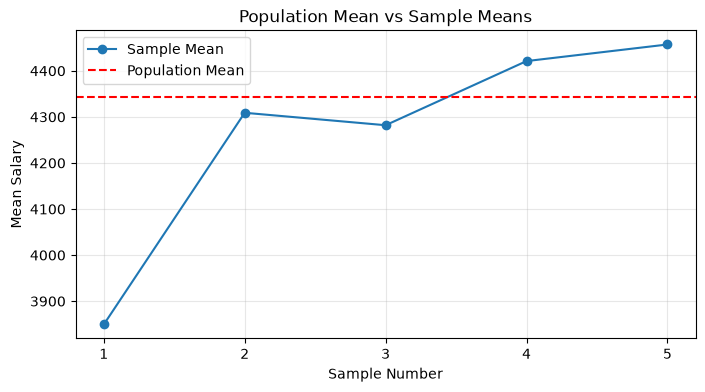

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    range(1, 6),
    sample_means,
    marker="o",
    label="Sample Mean"
)

plt.axhline(
    population_mean,
    color="red",
    linestyle="--",
    label="Population Mean"
)

plt.xticks(range(1, 6))
plt.xlabel("Sample Number")
plt.ylabel("Mean Salary")
plt.title("Population Mean vs Sample Means")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

---
#### 실습문제


A. 개념 이해
1. 기술통계와 추론통계의 가장 큰 차이점을 설명
    - 기술통계 : 내가 가지고 있는 데이터로 알 수 있는 정보(평균, 중앙값, 최대, 최소 등..)
    - 추론통계 : 내가 가지고 있는 표본들로 인해 예측해볼 수 있는 모집단의 정보

2. 회사 직원 500명 중 50명을 조사해 평균 급여를 계산했다. 모집단, 표본, 모수, 통계량은 각각 무엇인지
    - 모집단 : 500명
    - 표본 : 50명
    - 모수 : 모집단의 특성을 나타내는 수치 (모집단의 평균)
    - 통계량 : 표본의 특성을 나타내는 수치 (표본의 평균)

3. 표본 평균이 모집단 평균과 같지 않은 이유를 설명
    - 표본은 모집단 그대로 가져온 것이 아니라 일부만 가져온 것이기 때문에 표본의 평균과 모집단의 평균은 같을 수도 있고 같지 않을수도 있다.

4. 표본을 무작위로 추출하는 이유는 무엇인지
    - 무작위 추출은 표본 선정 과정에서 특정 집단이 유리하거나 불리하지 않게 하기 위해 무작위로 추출한다. (표본 편향을 방지)

In [16]:
# B. 모집단과 표본 평균 비교
import numpy as np

population = np.array([
    2500, 2700, 2900, 3000, 3200,
    3300, 3500, 3700, 4000, 4200,
    4500, 4700, 5000, 5300, 6000
])

# 실습 문제 7개
# 1. 모집단의 데이터 개수 확인
print(len(population))

# 2. 모집단의 평균 계산
print(population.mean())

# 3. 표본 5개 무작위 추출
rng = np.random.default_rng(42)
sample = rng.choice(population, size=5, replace=False)
print(sample)

# 4. 표본 평균 계산
print(sample.mean())

# 5. 모집단 평균과 표본 평균의 차이 계산
print(population.mean() - sample.mean())

# 6. 표본을 100번 추출하기
rng = np.random.default_rng(42)
sample_means = []
for i in range(100):

    sample = rng.choice(population, size=5, replace=False)
    sample_means.append(sample.mean())

# 7. 표본 평균들의 평균 계산
print("표본들의 평균 :", np.mean(sample_means))
print("모집단의 평균 :", population.mean())

15
3900.0
[4200 3500 4000 2500 6000]
4040.0
-140.0
표본들의 평균 : 3896.8
모집단의 평균 : 3900.0


C. 분석 및 해석 문제
1. 표본을 100번 추출했을 때 모든 표본 평균이 동일하게 나올까? 그 이유는 무엇일까?
    - 동일하게 나오지 않는다. 표본 변동성이 발생하기 때문에

2. 100개의 표본 평균을 다시 평균 낸 값은 모집단 평균과 정확하게 일치해야 할까?
    - 정확하게 일치할수도 있고 아닐수도 있다.

3. 표본 크기를 5개에서 10개로 증가시키면 표본 평균의 변동성은 일반적으로 어떻게 달라질까? 그 이유는 무엇일까?
    - 표본 변동성이 감소한다.